# 03 · MSP, mandi prices, cost of cultivation and rainfall
Four supporting datasets, each with its own trap: MSP year conventions and bonuses, mandi commodity forms, sparse cost coverage, and rainfall at subdivision (not state) level.

| | |
|---|---|
| **Objective** | Build the price, cost and weather inputs. |
| **Dataset** | Official MSP 2002-03..2026-27, AGMARKNET and Maharashtra APMC prices, DES cost of cultivation, IMD rainfall, CPI. |
| **Business question** | Which MSP applies to a given sale date, and which price forms are comparable with MSP? |
| **Method** | Marketing-season rule, MSP-comparable price forms, outlier rules, seasonal rainfall metrics. |
| **Output** | fact_msp, fact_market_price, fact_cost_of_cultivation, weather facts. |
| **Key finding** | Using the wrong MSP year mis-states the below-MSP share by one year's MSP hike (often 5-10%). |

In [1]:
import sys, sqlite3, warnings
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore")
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
from src.config import RAW, CURATED, PROC, RESULTS, FIGURES, DB_PATH, connect_ro
pd.set_option("display.max_columns", 40); pd.set_option("display.width", 200)
BLUE, ORANGE, AQUA, YELLOW, PINK, RED, GREY = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#e34948", "#9aa19c"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": .25, "axes.titleweight": "bold", "axes.titlesize": 11})
def save(fig, name):
    fig.savefig(FIGURES / f"{name}.png", bbox_inches="tight"); plt.show()
from src import build_msp, build_prices, build_costs_weather
from src.build_prices import msp_crop_year

## 1. Official MSP series
`crop_year` = first year of the agricultural year. Rabi MSPs are aligned so wheat **sown** in 2016-17 (RMS 2017-18) sits in crop year 2016. Every value carries its source URL.

In [2]:
msp = build_msp.main()
msp.pivot_table(index="msp_key", columns="crop_year", values="msp_effective").loc[["Paddy", "Wheat", "Cotton", "Gram", "Tur", "Soyabean", "Sugarcane"], 2004:2024]

516 MSP rows


crop_year,2004,2005,2006,2007,2008,2009,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024
msp_key,,,,,,,,,,,,,,,,,,,,,
Paddy,560.0,570.0,580.00,645.00,850.00,950.00,1000.00,1080.0,1250.0,1310.0,1360.0,1410.0,1470.0,1550.0,1750.0,1815.0,1868.0,1940.0,2040.0,2183.0,2300.0
Wheat,640.0,650.0,750.00,1000.00,1080.00,1100.00,1120.00,1285.0,1350.0,1400.0,1450.0,1525.0,1625.0,1735.0,1840.0,1925.0,1975.0,2015.0,2125.0,2275.0,2425.0
Cotton,1760.0,1760.0,1770.00,1800.00,2500.00,2500.00,2500.00,2800.0,3600.0,3700.0,3750.0,3800.0,3860.0,4020.0,5150.0,5255.0,5515.0,5726.0,6080.0,6620.0,7121.0
Gram,1425.0,1435.0,1445.00,1600.00,1730.00,1760.00,2100.00,2800.0,3000.0,3100.0,3175.0,3500.0,4200.0,4400.0,4620.0,4875.0,5100.0,5230.0,5335.0,5440.0,5650.0
Tur,1390.0,1400.0,1410.00,1550.00,2000.00,2300.00,3000.00,3200.0,3850.0,4300.0,4350.0,4425.0,5050.0,5450.0,5675.0,5800.0,6000.0,6300.0,6600.0,7000.0,7550.0
Soyabean,1000.0,1010.0,1020.00,1050.00,1390.00,1390.00,1440.00,1690.0,2240.0,2560.0,2560.0,2600.0,2775.0,3050.0,3399.0,3710.0,3880.0,3950.0,4300.0,4600.0,4892.0
Sugarcane,74.5,79.5,80.25,81.18,81.18,129.84,139.12,145.0,170.0,210.0,220.0,230.0,230.0,255.0,275.0,275.0,NaN,NaN,NaN,NaN,NaN


In [3]:
display(msp.groupby(["source_id", "verification"]).agg(values=("msp_key", "size"), first=("crop_year", "min"), last=("crop_year", "max")))
pd.read_csv(PROC / "dq_msp_crosscheck_2013.csv").query("match == False")

,,values,first,last
source_id,verification,,,
CMO_2012_16,official,89,2012,2016
DES_KH_2016,official,14,2016,2016
NEWS_FRP_2019,secondary,1,2019,2019
NEWS_JUTE_2018,secondary,1,2017,2017
NEWS_RB_2027,secondary,6,2026,2026
OGD_2002_12,official,197,2002,2011
PIB_2013_vs_2024,official,15,2013,2024
PIB_ALL_2021_23,official,63,2021,2023
PIB_FRP_2018,official,2,2017,2018


,msp_key,cmo_2013,pib_2013,match,resolution,reason
0,Bajra,1310.0,1250.0,False,use PIB 1250,CMO 1310 equals the maize MSP (copy error in C...
14,Sesamum,4500.0,2500.0,False,keep CMO 4500,PIB value 2500 breaks the series 4200 (2012) -...


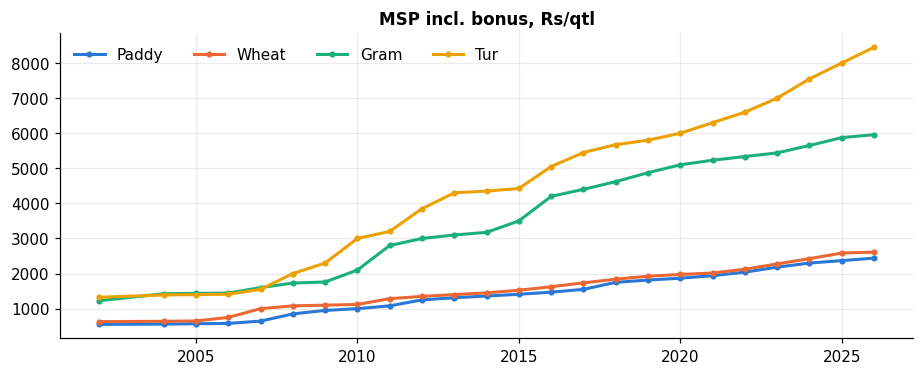

In [4]:
fig, ax = plt.subplots(figsize=(10, 3.6))
for k, col in [("Paddy", BLUE), ("Wheat", ORANGE), ("Gram", AQUA), ("Tur", YELLOW)]:
    s = msp[msp.msp_key == k].set_index("crop_year").msp_effective
    ax.plot(s.index, s.values, color=col, lw=2, marker="o", ms=3, label=k)
ax.set_title("MSP incl. bonus, Rs/qtl"); ax.legend(frameon=False, ncol=4)
save(fig, "03_msp_series")

## 2. Mandi prices: which quotes can be compared with MSP?
The MSP that applies to a sale depends on the **marketing season** of the sale date (kharif Oct–Sep, rabi Apr–Mar).

In [5]:
for crop, d in [("Wheat", "2015-05-01"), ("Wheat", "2015-02-01"), ("Rice", "2024-09-30"), ("Rice", "2024-10-01")]:
    print(f"{crop:6s} sold {d}: MSP of crop year {msp_crop_year(crop, pd.Timestamp(d))}")
build_prices.main()
price = pd.read_csv(PROC / "fact_market_price.csv", dtype={"variety": str})
price.groupby(["source_dataset", "price_form", "msp_comparable"]).size().rename("quotes").reset_index().sort_values("quotes", ascending=False).head(15)

Wheat  sold 2015-05-01: MSP of crop year 2014
Wheat  sold 2015-02-01: MSP of crop year 2013
Rice   sold 2024-09-30: MSP of crop year 2023
Rice   sold 2024-10-01: MSP of crop year 2024


{'price_rows': 106885, 'rows_in': 106885, 'markets': 3418, 'flagged_or_excluded': 774}
dq_flag
flag: min/modal/max inconsistent (spread not computed)    464
excluded: modal >5x or <1/5 of commodity median           265
excluded: modal <= 0                                       45
Name: count, dtype: int64


,source_dataset,price_form,msp_comparable,quotes
21,AGMARKNET daily Jul-Sep 2026,Onion,False,14287
25,AGMARKNET daily Jul-Sep 2026,Potato,False,13990
36,AGMARKNET daily Jul-Sep 2026,Wheat grain,True,8759
24,AGMARKNET daily Jul-Sep 2026,Paddy (common),True,5535
74,MH APMC monthly (CMO) 2014-16,Gram (whole),True,4115
95,MH APMC monthly (CMO) 2014-16,Wheat grain,True,4097
89,MH APMC monthly (CMO) 2014-16,Soyabean,True,3727
76,MH APMC monthly (CMO) 2014-16,Jowar (mixed varieties),True,3716
92,MH APMC monthly (CMO) 2014-16,Tur (whole),True,3477
13,AGMARKNET daily Jul-Sep 2026,Maize,True,3460


In [6]:
pd.read_csv(PROC / 'dq_price_issues.csv').dq_flag.value_counts()

dq_flag
flag: min/modal/max inconsistent (spread not computed)    464
excluded: modal >5x or <1/5 of commodity median           265
excluded: modal <= 0                                       45
Name: count, dtype: int64

## 3. Cost of cultivation: what actually exists

In [7]:
coc = build_costs_weather.build_costs()
coc.pivot_table(index="crop_name", columns="state_name", values="c2_per_ha", aggfunc="count").fillna(0).astype(int)

cost rows 300 | crops 10 | states 13


state_name,Andhra Pradesh,Bihar,Gujarat,Haryana,Karnataka,Madhya Pradesh,Maharashtra,Odisha,Punjab,Rajasthan,Tamil Nadu,Uttar Pradesh,West Bengal
crop_name,,,,,,,,,,,,,
Arhar/Tur,6,0,6,0,6,0,6,0,0,0,0,6,0
Cotton,6,0,6,6,0,0,6,0,6,0,0,0,0
Gram,6,0,0,0,0,5,6,0,0,6,0,6,0
Groundnut,6,0,6,0,6,0,6,0,0,0,6,0,0
Maize,6,6,0,0,6,0,0,0,0,6,0,6,0
Moong,6,0,0,0,6,0,6,6,0,6,0,0,0
Rapeseed & Mustard,0,0,6,6,0,6,0,0,0,6,0,6,0
Rice,6,0,0,0,0,0,0,6,6,0,0,6,6
Sugarcane,6,0,0,0,6,0,6,0,0,0,6,6,0


Only 10 crops × 5 states × 6 years. Profit is computed **only** for these cells, with no projection or interpolation.

## 4. Rainfall: state series from IMD subdivisions

subdivision-years 4116 | state-years 910


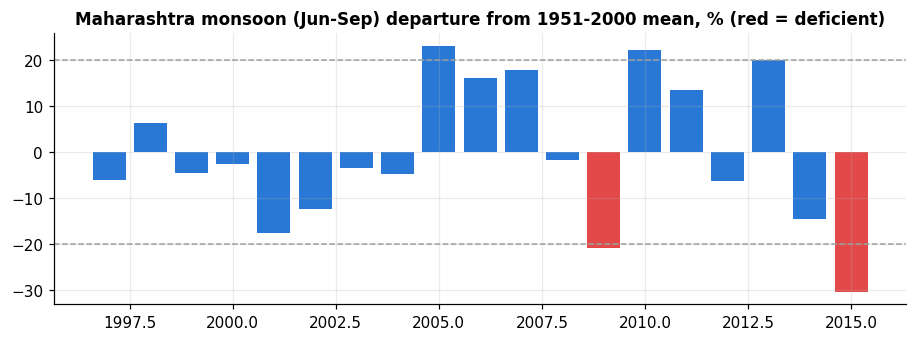

In [8]:
build_costs_weather.build_weather()
w = pd.read_csv(PROC / "fact_weather_state.csv")
s = w[(w.state_name == "Maharashtra") & w.crop_year.between(1997, 2015)]
fig, ax = plt.subplots(figsize=(10, 3.2))
ax.bar(s.crop_year, s.jjas_dep_pct, color=[RED if v <= -20 else BLUE for v in s.jjas_dep_pct])
ax.axhline(-20, color=GREY, ls="--", lw=1); ax.axhline(20, color=GREY, ls="--", lw=1)
ax.set_title("Maharashtra monsoon (Jun-Sep) departure from 1951-2000 mean, % (red = deficient)")
save(fig, "03_mh_monsoon")

## Conclusion
MSP, prices, costs and rainfall are aligned on crop year and marketing season.

## Limitations
Mandi prices cover Maharashtra 2014-16, one day in 2024 and Jul-Sep 2026; rainfall ends in 2015; cost data only 2008-2013.

## Next steps
Longer AGMARKNET history via the data.gov.in API; district rainfall.